# Kaggle Playground Series S6E11: Fraud Detection

This notebook demonstrates a complete end-to-end pipeline to predict fraudulent transactions using a Deep Learning Neural Network built with TensorFlow/Keras.

### Notebook Overview:
* **Data Download**: Retrieving competition data via the `kagglehub` API.
* **Exploratory Data Analysis (EDA)**: Understanding dataset shapes, columns, and value distributions.
* **Preprocessing**: Standardizing numerical columns and encoding categorical variables using scikit-learn Pipelines.
* **Model Building**: Designing a Deep Neural Network (DNN) with regularization techniques like Dropout and Batch Normalization to combat overfitting.
* **Evaluation**: Evaluating performance using the ROC AUC metric.
* **Submission**: Making predictions on unseen test data and exporting the results.

In [1]:
import kagglehub
kagglehub.login()

Kaggle credentials set.
Kaggle credentials successfully validated.


In [2]:
path = kagglehub.competition_download('playground-series-s6e11')

100%|██████████| 29.5M/29.5M [00:00<00:00, 187MB/s]

Extracting files...


In [3]:
import os
os.listdir(path)

['train.csv', 'sample_submission.csv', 'test.csv']

In [4]:
train_path = os.path.join(path, 'train.csv')
test_path = os.path.join(path, 'test.csv')


In [5]:
import pandas as pd
pd.set_option('display.max_columns', None)
df = pd.read_csv(train_path)
df.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


# 1_Preprocessing

## Phase 1: Data Preprocessing

To prepare the tabular dataset for our Neural Network, we apply the following strategies:

* **Feature Split**: Segregate numerical features from categorical/boolean features.
* **Standardization**: Apply `StandardScaler` to numerical inputs to ensure all continuous features have a mean of 0 and variance of 1.
* **One-Hot Encoding**: Apply `OneHotEncoder` to nominal categories and boolean attributes to avoid implying arbitrary ordinal relationships.
* **Column Transformer Pipeline**: Package the transformations into a single, clean `ColumnTransformer` object to prevent data leakage and facilitate seamless inference.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-nul

In [7]:
df.describe()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000
mean,349979.500000,79.893068,6.633734,2.984092,13.587575,46.862982,51.430286,2064.998070,0.085472,18.929445,11.761915,2.981733,35.217648,0.152769,0.016700
std,202061.191548,205.173538,6.290133,1.498998,11.617325,5.579190,17.899150,3400.132922,0.289524,10.864385,6.869164,2.001652,12.628361,0.381126,0.128143
min,0.000000,1.000000,0.010000,0.000000,0.000000,25.000000,18.000000,58.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,174989.750000,15.810000,2.110000,2.000000,4.430000,43.000000,38.000000,834.120000,0.000000,11.400000,6.000000,1.000000,26.400000,0.000000,0.000000
50%,349979.500000,27.250000,4.730000,3.000000,10.220000,47.000000,52.000000,1382.740000,0.000000,18.600000,12.000000,3.000000,34.200000,0.000000,0.000000
75%,524969.250000,43.110000,9.190000,4.000000,19.750000,51.000000,66.000000,2517.020000,0.000000,26.000000,18.000000,5.000000,42.700000,0.000000,0.000000
max,699959.000000,6872.690000,51.980000,11.000000,57.930000,73.000000,81.000000,99701.390000,3.000000,72.900000,23.000000,6.000000,100.000000,4.000000,1.000000


In [8]:
df.isnull().sum()[df.isnull().sum()>0]

,0


In [9]:
cat_cols = df.select_dtypes([object, bool
                             ]).columns.to_list()
cat_cols

['merchant_category',
 'card_type',
 'auth_method',
 'channel',
 'device_type',
 'is_foreign_transaction',
 'is_new_merchant',
 'used_vpn',
 'ip_country_mismatch',
 'billing_shipping_mismatch',
 'is_ai_generated_scam_attempt']

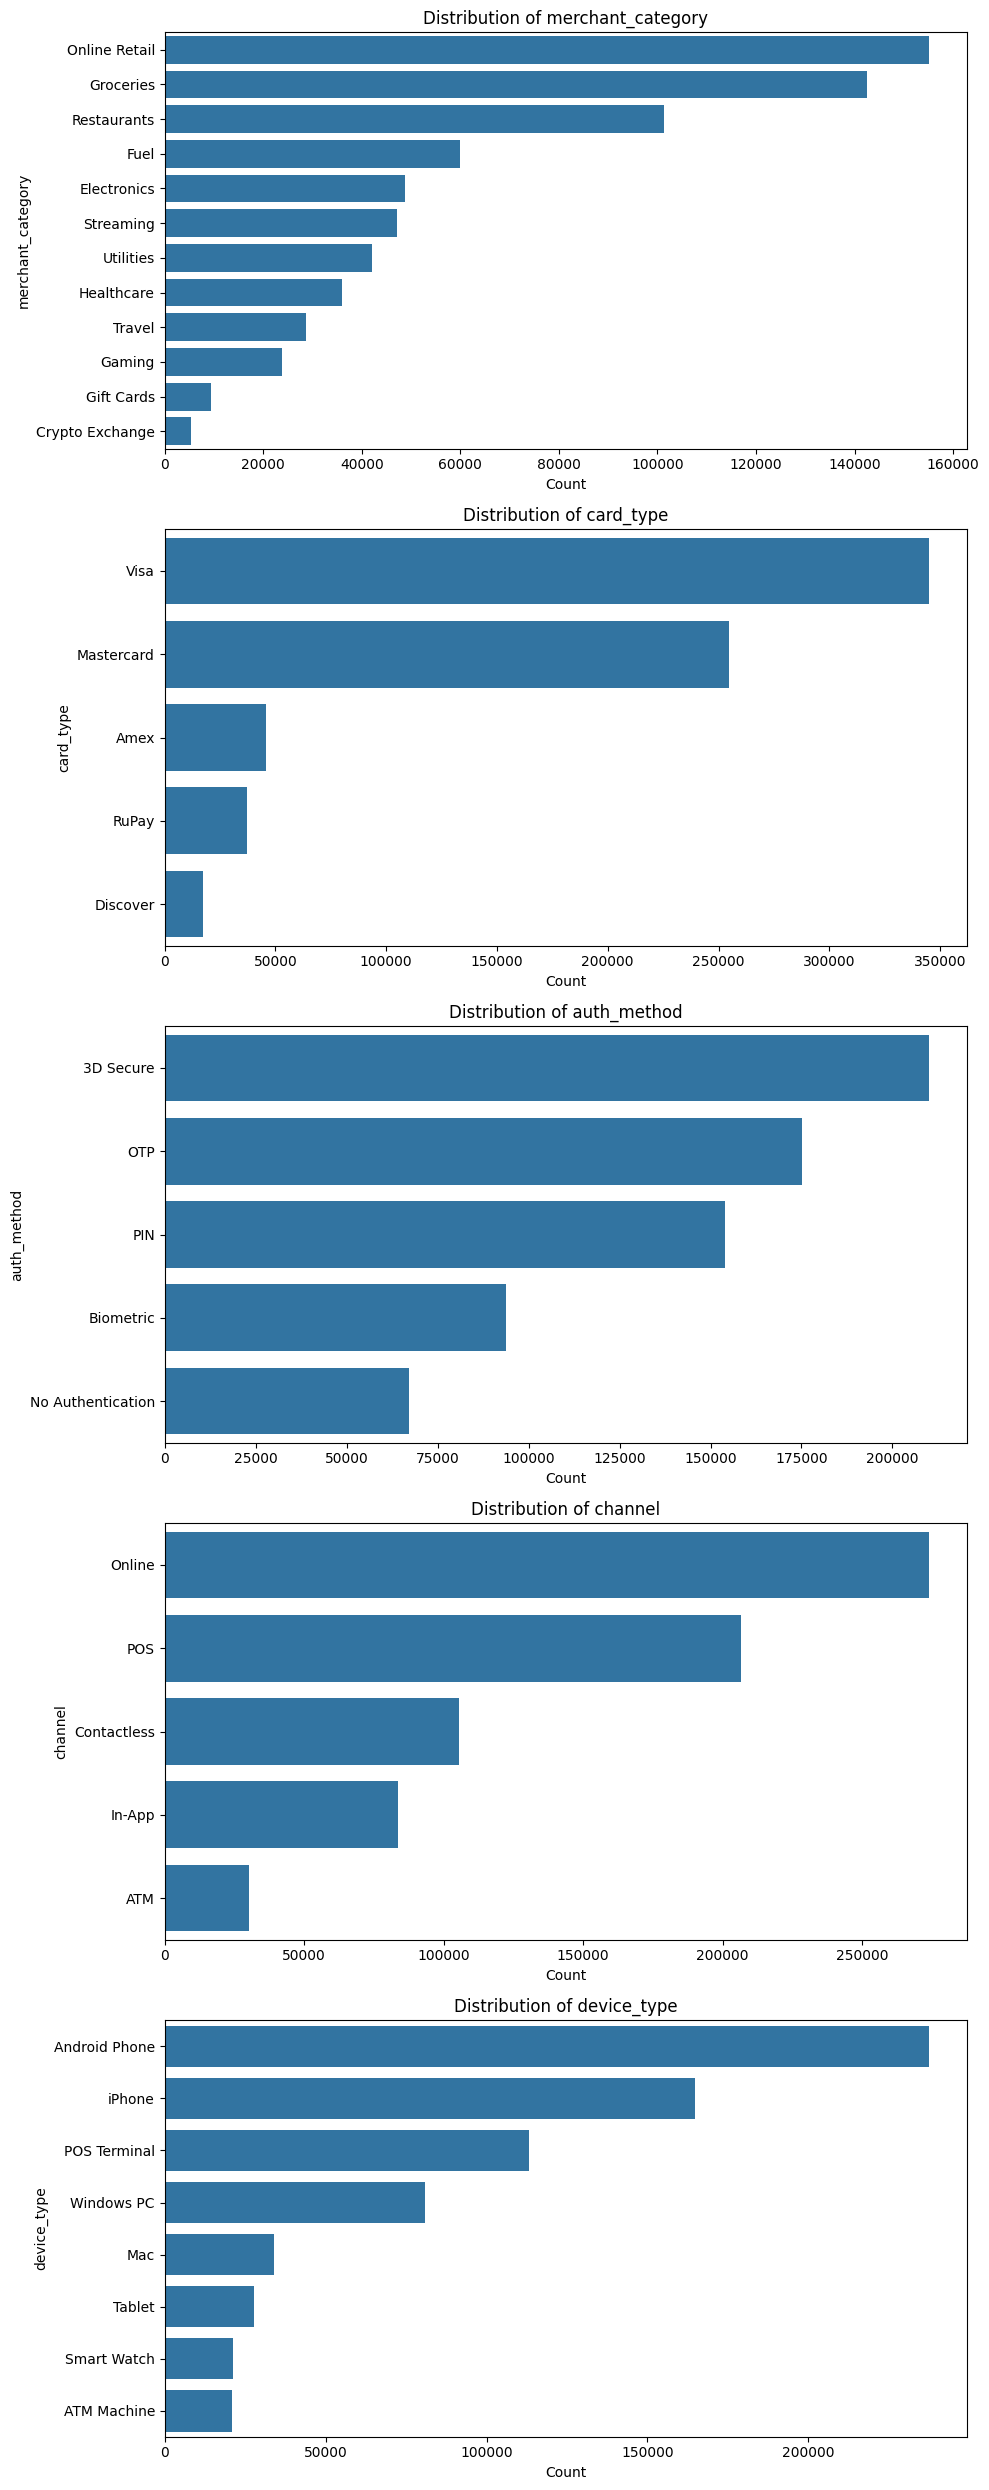

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

cat_features = df.select_dtypes(include=['object', 'category']).columns.tolist()

fig, axes = plt.subplots(len(cat_features), 1, figsize=(10, 5 * len(cat_features)))
if len(cat_features) == 1:
    axes = [axes]

for ax, col in zip(axes, cat_features):
    sns.countplot(data=df, y=col, ax=ax, order=df[col].value_counts().index)
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel('Count')
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()


| Model Type | Best Choice | Why |
| :--- | :--- | :--- |
| **Random Forest, XGBoost, LightGBM** | Label Encoding | Trees split efficiently on integer codes; avoids sparse matrices. |
| **Neural Networks, Logistic Regression, SVM** | One-Hot Encoding | Prevents the model from misinterpreting arbitrary integer ranks as mathematical magnitude. |


In [11]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

num_cols = df.select_dtypes([int, float]).columns.tolist()
if 'is_fraud' in num_cols:
    num_cols.remove('is_fraud')
char_cols = df.select_dtypes([object, bool]).columns.tolist()

numerical_transformer = Pipeline(steps = [
    ('scaler', StandardScaler())
])

char_transformation = Pipeline(steps = [
    ('encoding', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])


preprocessing  = ColumnTransformer(
    transformers=[
        ('drop_cols', 'drop', ['id']),
        ('num', numerical_transformer, num_cols),
        ('char', char_transformation, char_cols)
    ],
    remainder='passthrough'
)

# 2_Model_Building


## Phase 2: Neural Network Architecture & Training

Since fraud detection is highly imbalanced, we build a robust architecture accompanied by specialized training weights:

* **Class Weight Balancing**: Compute class weights dynamically using scikit-learn to penalize minority class errors heavily during optimization.
* **Network Layers**:
  * Dense inputs expanded to `256` hidden units.
  * Progressively narrower layers (`128` units, `64` units) to learn condensed representation spaces.
  * **Batch Normalization** applied at each layer to stabilize and accelerate training.
  * **Dropout Regularization** (rates from `0.4` to `0.2`) to mitigate overfitting on training data.
* **Optimization**: Binary cross-entropy loss optimized via Adam with early stopping monitored on validation AUC.

In [12]:
X = df.drop('is_fraud', axis = 1)
y = df['is_fraud']

In [14]:
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from sklearn.utils import compute_class_weight
import numpy as np
from tensorflow.keras.layers import BatchNormalization

# 1. Apply your preprocessing to get the final numeric matrix X_processed
X_processed = preprocessing.fit_transform(X)  # Shape will be (699960, 50)

# 2. Perform a Train-Test Split for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_processed, y, test_size=0.2, random_state=42, stratify=y
)


# Calculate class weights automatically
class_weights = compute_class_weight(
    class_weight="balanced", classes=np.unique(y_train), y=y_train
)
weight_dict = dict(enumerate(class_weights))
print(f"Calculated Class Weights: {weight_dict}")


# 3. Build the Neural Network with the correct input dimension (50)
model = Sequential(
    [
        Dense(
            256,
            input_dim=X_train.shape[1],
            activation="relu",
            kernel_initializer="he_normal",
        ),
        BatchNormalization(),
        Dropout(0.4),
        Dense(
            128, activation="relu", kernel_initializer="he_normal"
        ),  # Wider layer
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation="relu", kernel_initializer="he_normal"),
        BatchNormalization(),
        Dropout(0.2),
        Dense(1, activation="sigmoid"),
    ]
)

model.compile(
    loss="binary_crossentropy",
    optimizer=Adam(learning_rate=0.001),  # Slightly lower learning rate for stability
    metrics=[tf.keras.metrics.AUC(name="auc")],
)

# 4. Train using the validation set (with Early Stopping recommended)
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_auc", mode="max", patience=5, restore_best_weights=True
)


history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,  # 500 is likely too high without early stopping
    batch_size=2048,  # Larger batch size speeds up training on 700k rows
    class_weight=weight_dict,
    callbacks=[early_stopping],
    verbose=1,
)

Calculated Class Weights: {0: np.float64(0.5084913833027312), 1: np.float64(29.941610522938724)}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step - auc: 0.8784 - loss: 0.4588 - val_auc: 0.9303 - val_loss: 0.3059
Epoch 2/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 19s 36ms/step - auc: 0.9206 - loss: 0.3619 - val_auc: 0.9368 - val_loss: 0.2863
Epoch 3/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 11s 41ms/step - auc: 0.9296 - loss: 0.3395 - val_auc: 0.9387 - val_loss: 0.2918
Epoch 4/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 11s 41ms/step - auc: 0.9346 - loss: 0.3268 - val_auc: 0.9392 - val_loss: 0.2845
Epoch 5/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 20s 41ms/step - auc: 0.9371 - loss: 0.3205 - val_auc: 0.9402 - val_loss: 0.2804
Epoch 6/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - auc: 0.9389 - loss: 0.3159 - val_auc: 0.9403 - val_loss: 0.2940
Epoch 7/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 11s 40ms/step - auc: 0.9404 - loss: 0.3119 - val_auc: 0.9398 - val_loss: 0.2845
Epoch 8/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 12s 42ms/step - auc: 0.9416 - loss: 0.3090 - val_auc: 0.9401 - val_loss: 0.3086
Epoch 9/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 

# 3_Model Evualiation

## Phase 3: Model Evaluation

In this phase, we analyze training behavior and check model performance metrics on unseen validation data:

* **Loss Curves Plotting**: Comparing training vs. validation loss curves over epochs to identify early stopping activation points.
* **Validation AUC-ROC Metric**: Measuring the overall discriminative capability of the network.

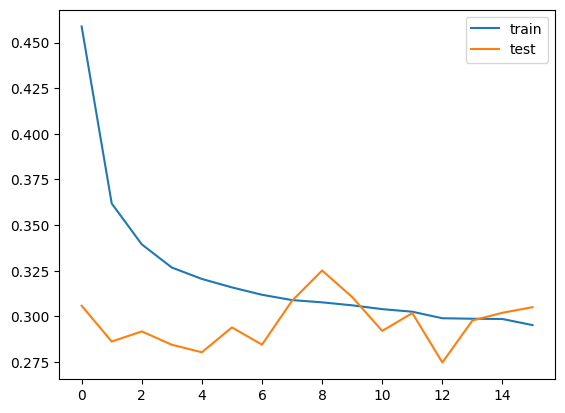

In [15]:
#early stopping graph
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label ='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
plt.show()

In [16]:
y_pred = model.predict(X_val)

4375/4375 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step


In [17]:
y_pred

array([[0.01338116],
       [0.0524149 ],
       [0.10287055],
       ...,
       [0.15432659],
       [0.01855594],
       [0.84287715]], shape=(139992, 1), dtype=float32)

In [18]:
from sklearn.metrics import roc_auc_score

auc_score = roc_auc_score(y_val, y_pred)
auc_score.mean()

np.float64(0.940326380297445)

# 4_Test.csv Prediction

## Phase 4: Scoring Test Data

Using the trained neural network model and preprocessing pipeline, we run inference on the official test dataset:

* **Consistency**: Transform the test DataFrame using the *already fitted* preprocessing transformer to prevent train-test contamination.
* **Inference**: Generate probability scores via `model.predict()`.

In [19]:
df_test = pd.read_csv(test_path)
df_test.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,699960,28.21,4.52,4,17.87,37,45,1483.49,0,15.4,21,3,22.1,0,Fuel,Visa,OTP,Online,iPhone,False,False,False,False,False,False
1,699961,644.90,5.48,1,6.68,52,28,2183.64,0,11.2,9,1,25.1,0,Travel,RuPay,PIN,Contactless,Android Phone,False,False,False,False,False,False
2,699962,20.53,12.20,3,15.39,44,75,1208.59,0,20.8,2,4,52.9,1,Gaming,Visa,No Authentication,Online,iPhone,False,False,False,False,False,False
3,699963,10.83,6.90,2,44.34,50,54,1790.85,0,9.2,8,5,35.4,0,Streaming,Mastercard,PIN,Contactless,Mac,False,False,False,False,False,False
4,699964,19.00,0.63,3,25.22,50,66,1676.18,0,20.0,14,5,44.5,0,Groceries,Mastercard,PIN,In-App,Android Phone,False,False,False,False,False,False


In [20]:
test_id = df_test['id']

In [21]:
test_final = preprocessing.fit_transform(df_test)
test_final

array([[-1.73204503, -0.25618162, -0.33623462, ...,  0.        ,
         0.        ,  0.        ],
       [-1.73203349,  2.7989526 , -0.18400018, ...,  0.        ,
         0.        ,  0.        ],
       [-1.73202194, -0.29422899,  0.88164087, ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [ 1.73202194, -0.17419152, -0.36160703, ...,  0.        ,
         0.        ,  0.        ],
       [ 1.73203349, -0.37805209, -0.77708017, ...,  0.        ,
         0.        ,  0.        ],
       [ 1.73204503, -0.24062579,  0.26477425, ...,  0.        ,
         0.        ,  0.        ]], shape=(299984, 50))

In [22]:
test_pred = model.predict(test_final)
test_pred

9375/9375 ━━━━━━━━━━━━━━━━━━━━ 13s 1ms/step


array([[0.00754149],
       [0.00164272],
       [0.8953183 ],
       ...,
       [0.6803689 ],
       [0.00343739],
       [0.0321574 ]], shape=(299984, 1), dtype=float32)

# 5_Submission.csv

## Phase 5: Submission Generation

Finally, we prepare the output file for leaderboard submission:

* Map the model probabilities back to the target column `is_fraud`.
* Verify formatting matches `sample_submission.csv`.
* Write out the file to `NN2_submission.csv`.

In [23]:
submission_path = os.path.join(path, 'sample_submission.csv')
submission_file = pd.read_csv(submission_path)
submission_file

,id,is_fraud
0,699960,0.0167
1,699961,0.0167
2,699962,0.0167
3,699963,0.0167
4,699964,0.0167
...,...,...
299979,999939,0.0167
299980,999940,0.0167
299981,999941,0.0167
299982,999942,0.0167


In [24]:
submission_df = pd.DataFrame(
    {'id': test_id, 'is_fraud': test_pred.flatten()}
)

submission_file_path = 'NN2_submission.csv'
submission_df.to_csv(submission_file_path, index=False)

submission_df.head()

,id,is_fraud
0,699960,0.007541
1,699961,0.001643
2,699962,0.895318
3,699963,0.054223
4,699964,0.077391
